# Baseline Atlas-DeePC

The current nominal baseline uses **$\lambda_g=0$**, 48 physical-configuration
charts, rank-60 uncentered linear subspaces, and iterative N=10 terminal-reference
augmentation. This notebook compares two algorithms on the same evaluation seeds:

1. **Atlas-DeePC without graph waypoints:** track the selected terminal reference
   from the first control step.
2. **Atlas-DeePC with graph waypoints:** track the next chart representative until
   the 7 cm terminal-mode latch, then track the selected terminal reference.

The main results and videos below use Clarabel. **Section 8** reports the matched
OSQP solver test, keeping the Clarabel results intact.

**Scope:** both algorithms retain graph-route-cost selection of the N=10 terminal
candidates. "Without graph waypoints" does not mean all graph information is
removed. Only the use of intermediate waypoint references changes. Because the
closed-loop trajectories differ, their subsequently selected terminal configurations
can differ too, despite using the same selection rule and candidate pool.

There is no contextual rescue, fitted dynamics, IK controller, added offline data,
or measurement noise. Every successful solve supplies an action through DeePC.
Unsolved QPs, if any, are reported rather than omitted. The old $\lambda_g=0.05$
notebook and its results remain archived; none of its outcome labels is reused here.


In [1]:
import json
import os
import sys
from pathlib import Path
from dataclasses import asdict
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
get_ipython().run_line_magic("matplotlib", "inline")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/baseline_atlas_deepc.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import baseline_atlas_deepc as baseline
import routed_deepc_experiment as experiment
import baseline_waypoint_comparison as comparison
DATA_PATH, ATLAS_PATH = baseline.DATA_PATH, baseline.ATLAS_PATH
RESULT_ROOT = comparison.RESULT_ROOT
EVALUATION_SEEDS = list(range(211, 1211))  # Stop is exclusive; edit this range.
RUN_EVALUATION = False
WORKERS = 4
assert EVALUATION_SEEDS and len(set(EVALUATION_SEEDS)) == len(EVALUATION_SEEDS)
config = baseline.default_config()
assert config.lam_g == 0
if RUN_EVALUATION:
    comparison.run_panel(EVALUATION_SEEDS, RESULT_ROOT, WORKERS)
H = np.load(DATA_PATH, mmap_mode="r")
atlas = experiment.load_atlas(ATLAS_PATH)
METHODS = comparison.METHODS
COLORS = {"terminal": "#D55E00", "graph": "#0072B2"}
print("Baseline version:", baseline.BASELINE_VERSION)
print(f"Evaluation: {len(EVALUATION_SEEDS)} paired seeds, {min(EVALUATION_SEEDS)}--{max(EVALUATION_SEEDS)}")


Baseline version: linear_iterative_n10_lamg0_v2
Evaluation: 1000 paired seeds, 211--1210


## 1. Linear-Subspace DeePC and References

For each chart, collect its complete offline columns $X_k$ and retain the leading
60 left singular vectors **without mean subtraction**. The QP uses the current
chart's cached basis $B_k$:

$$\begin{bmatrix}u_{\rm ini}\\u\\y_{\rm ini}+\sigma\\y\end{bmatrix}=B_k g.$$

There is no affine offset, sum-to-one constraint, or coefficient-norm penalty.
The empirical coefficient bounds remain in place. All $U_p,U_f,Y_p,Y_f$ rows are
retained. Q, R, past-output slack and input-smoothness penalties remain unchanged:

$$Q=\operatorname{diag}(5000I_4,20I_2,10^5I_2,5000I_2),\quad R=10^{-4}I_2,$$
$$\lambda_g=0,\quad\lambda_{\rm ini}=10^5,\quad\lambda_{\Delta u}=5.$$

Both methods use two past steps, a ten-step prediction horizon, input limits
$[-1,1]$, and 320 control steps. The additional terminal cost is zero.

### Common Iterative Terminal Reference

1. Once the target is known, find the ten eligible offline configurations with
   closest fingertips. Exclude source episodes with original targets within 6 cm
   of the online target. Deduplicate candidates by chart.
2. Each step, locate the current chart and select the candidate chart with minimum
   directed route cost. Ties use fingertip error and source index.
3. The selected candidate supplies the posture; velocities are set to zero and
   fingertip coordinates to the requested target. Candidate selection continues
   throughout both rollouts, including after the waypoint method's 7 cm latch.

The one-time candidate search is shared in definition, not an online trajectory
retrieval. The graph provides references, never control actions.


In [2]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=1):
    controller = baseline.BaselineAtlasDeePC(H, atlas, config)
assert len(controller.matrix_cache) == 48
assert all(not np.any(m["offset"]) and m["basis"].shape == (144, 60)
           and "g_sum" not in m for m, _ in controller.matrix_cache.values())
display(pd.Series({"charts": config.clusters, "linear-subspace rank": config.svd_rank,
    "lambda_g": config.lam_g, "candidate count": baseline.CANDIDATE_COUNT,
    "DeePC matrix": "current chart only", "terminal-reference selection": "iterative minimum route cost",
    "changed component between methods": "intermediate graph waypoint references only"}))


charts                                                                        48
linear-subspace rank                                                          60
lambda_g                                                                     0.0
candidate count                                                               10
DeePC matrix                                                  current chart only
terminal-reference selection                        iterative minimum route cost
changed component between methods    intermediate graph waypoint references only
dtype: object

## 2. Inspecting the constructed physical-configuration atlas

A chart is defined by K-means on the latest periodic joint configuration

$$
\phi(y_t)=[\cos q_1,\cos q_2,\sin q_1,\sin q_2,\cos(q_1+q_2),\sin(q_1+q_2)].
$$

Inputs, velocities, fingertip coordinates, and the preceding output are not used to assign charts. Each panel below overlays 32 randomly sampled chart members in a shallow color and draws the chart medoid boldly. This is the updated 48-chart version of the configuration-cloud plot.


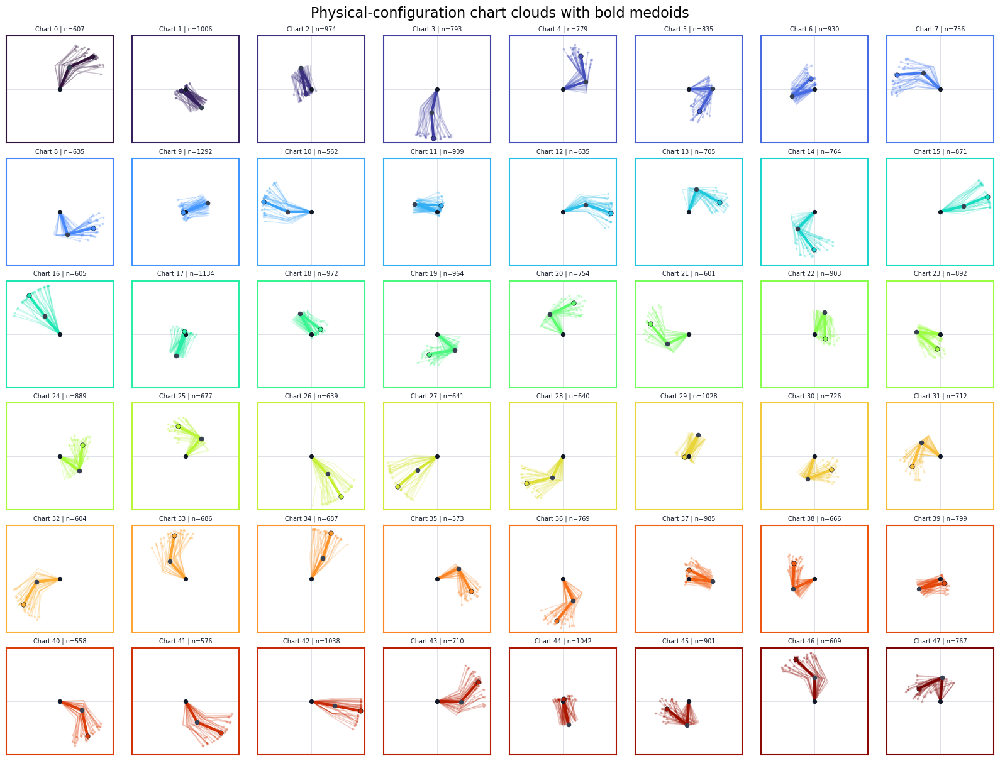

Medoid forward-kinematics consistency: max 0.505 mm
Chart occupancy: min 558, median 760, max 1292 windows


In [3]:
from matplotlib.collections import LineCollection

chart_sizes = np.bincount(atlas["labels"].astype(int), minlength=config.clusters)
medoid_states = np.asarray(atlas["medoid_states"], dtype=float)
chart_colors = plt.cm.turbo(np.linspace(0.0, 1.0, config.clusters))
chart_output_states = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)[experiment.pipe.T_INI - 1].T
cloud_members_per_chart = 32
cloud_rng = np.random.default_rng(17)

# Reacher-v5's output geometry is approximately 0.10 m to the elbow and
# 0.11 m from the elbow to the reported fingertip site.
link_1, link_2 = 0.10, 0.11
elbows = link_1 * np.column_stack([medoid_states[:, 0], medoid_states[:, 2]])
fk_fingertips = elbows + link_2 * np.column_stack([medoid_states[:, 8], medoid_states[:, 9]])
stored_fingertips = medoid_states[:, 6:8]
fk_error = np.linalg.norm(fk_fingertips - stored_fingertips, axis=1)

fig, axes = plt.subplots(6, 8, figsize=(16, 12), constrained_layout=True)
for chart_id, ax in enumerate(axes.flat):
    elbow = elbows[chart_id]
    fingertip = stored_fingertips[chart_id]
    color = chart_colors[chart_id]
    member_indices = np.flatnonzero(atlas["labels"] == chart_id)
    sampled_indices = cloud_rng.choice(
        member_indices, size=min(cloud_members_per_chart, member_indices.size), replace=False
    )
    cloud_states = chart_output_states[sampled_indices]
    cloud_elbows = link_1 * np.column_stack([cloud_states[:, 0], cloud_states[:, 2]])
    cloud_fingertips = cloud_states[:, 6:8]
    cloud_segments = np.stack([
        np.zeros_like(cloud_elbows), cloud_elbows, cloud_fingertips
    ], axis=1)
    ax.add_collection(LineCollection(
        cloud_segments, colors=[color], linewidths=1.05, alpha=0.24, zorder=1
    ))
    ax.scatter(cloud_fingertips[:, 0], cloud_fingertips[:, 1], s=7,
               color=color, alpha=0.32, linewidth=0, zorder=1)
    ax.plot([0, elbow[0], fingertip[0]], [0, elbow[1], fingertip[1]],
            color=color, linewidth=3.0, solid_capstyle="round", zorder=3)
    ax.scatter([0], [0], s=18, color="#111827", zorder=3)
    ax.scatter([elbow[0]], [elbow[1]], s=20, color="#374151", zorder=3)
    ax.scatter([fingertip[0]], [fingertip[1]], s=28, color=color,
               edgecolor="#111827", linewidth=0.5, zorder=4)
    ax.axhline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.axvline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.set_xlim(-0.225, 0.225)
    ax.set_ylim(-0.225, 0.225)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Chart {chart_id} | n={chart_sizes[chart_id]}", fontsize=7, color="#111827")
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(1.5)
fig.suptitle("Physical-configuration chart clouds with bold medoids", fontsize=16)
medoid_plot_path = RESULT_ROOT / "physical48_chart_configuration_clouds.png"
fig.savefig(medoid_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Medoid forward-kinematics consistency: max {1000 * fk_error.max():.3f} mm")
print(f"Chart occupancy: min {chart_sizes.min()}, median {np.median(chart_sizes):.0f}, max {chart_sizes.max()} windows")


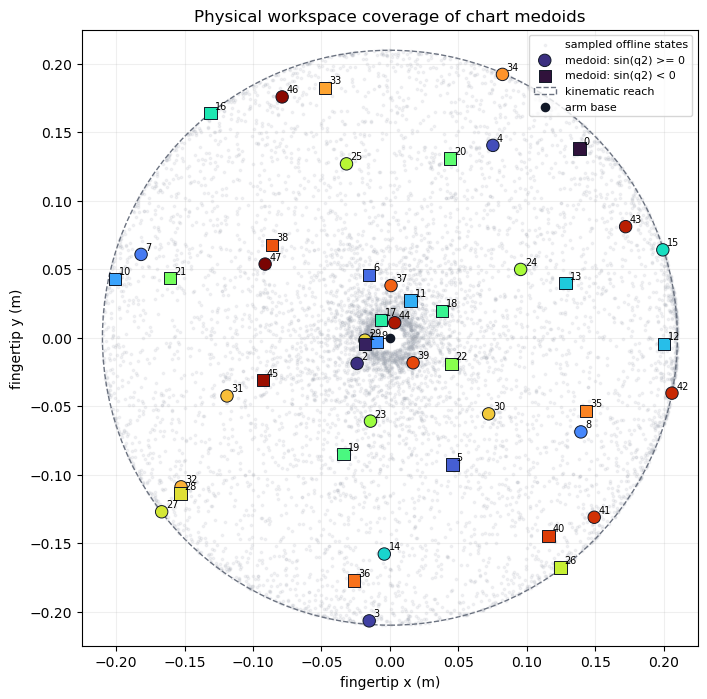

In [4]:
Y_windows = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)
offline_fingertips = Y_windows[experiment.pipe.T_INI - 1, 6:8].T
workspace_sample = np.linspace(0, offline_fingertips.shape[0] - 1, 8000, dtype=int)
elbow_up = medoid_states[:, 3] >= 0.0  # sign of sin(q2)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(offline_fingertips[workspace_sample, 0], offline_fingertips[workspace_sample, 1],
           s=3, color="#9ca3af", alpha=0.12, label="sampled offline states")
for mask, marker, label in [(elbow_up, "o", "medoid: sin(q2) >= 0"),
                            (~elbow_up, "s", "medoid: sin(q2) < 0")]:
    ax.scatter(stored_fingertips[mask, 0], stored_fingertips[mask, 1],
               c=chart_colors[mask], marker=marker, s=80, edgecolor="#111827",
               linewidth=0.7, label=label, zorder=3)
for chart_id, (x, y) in enumerate(stored_fingertips):
    ax.annotate(str(chart_id), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.add_patch(plt.Circle((0, 0), link_1 + link_2, fill=False, linestyle="--",
                        color="#6b7280", linewidth=1, label="kinematic reach"))
ax.scatter([0], [0], color="#111827", s=35, label="arm base", zorder=4)
ax.set_aspect("equal")
ax.set_xlim(-0.225, 0.225)
ax.set_ylim(-0.225, 0.225)
ax.set_xlabel("fingertip x (m)")
ax.set_ylabel("fingertip y (m)")
ax.set_title("Physical workspace coverage of chart medoids")
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=8)
workspace_plot_path = RESULT_ROOT / "atlas_workspace_coverage.png"
fig.savefig(workspace_plot_path, dpi=160, bbox_inches="tight")
plt.show()

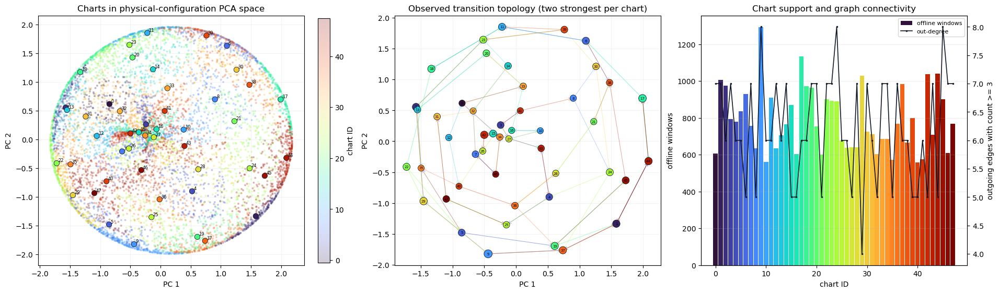

Active clustering coordinates: 6
PCA variance captured: 38.1%
Directed routing edges retained by the controller: 298
Outgoing-degree range: 4 to 8


In [5]:
from sklearn.decomposition import PCA

clustering_features, _, _ = experiment.behavioral_features(
    H,
    config.clustering_input_weight,
    config.clustering_feature_mode,
    config.clustering_configuration_weight,
    config.clustering_velocity_weight,
    config.clustering_fingertip_weight,
)
active_feature_mask = clustering_features.std(axis=0) > 1e-10
gate_features = clustering_features[:, active_feature_mask]
gate_centers = atlas["centers"][:, active_feature_mask]
pca = PCA(n_components=2)
gate_pca = pca.fit_transform(gate_features)
center_pca = pca.transform(gate_centers)
history_sample = np.linspace(0, gate_pca.shape[0] - 1, 8000, dtype=int)
transition_counts = np.asarray(atlas["transition_counts"], dtype=int)
edge_mask = transition_counts >= config.edge_count_threshold
np.fill_diagonal(edge_mask, False)
out_degree = edge_mask.sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
scatter = axes[0].scatter(gate_pca[history_sample, 0], gate_pca[history_sample, 1],
                          c=atlas["labels"][history_sample], cmap="turbo",
                          vmin=-0.5, vmax=config.clusters - 0.5, s=4, alpha=0.22)
axes[0].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=55,
                edgecolor="#111827", linewidth=0.6)
for chart_id, (x, y) in enumerate(center_pca):
    axes[0].annotate(str(chart_id), (x, y), xytext=(2, 2),
                     textcoords="offset points", fontsize=6)
axes[0].set_title("Charts in physical-configuration PCA space")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[0].grid(alpha=0.15)
fig.colorbar(scatter, ax=axes[0], label="chart ID", fraction=0.046)

# Show the two strongest observed outgoing transitions per chart. The router
# itself retains every edge meeting the count threshold.
for source in range(config.clusters):
    destinations = np.flatnonzero(edge_mask[source])
    if destinations.size:
        strongest = destinations[np.argsort(transition_counts[source, destinations])[-2:]]
        for destination in strongest:
            strength = transition_counts[source, destination]
            axes[1].annotate("", xy=center_pca[destination], xytext=center_pca[source],
                             arrowprops=dict(arrowstyle="->", color=chart_colors[source],
                                             alpha=min(0.75, 0.18 + strength / 250),
                                             linewidth=0.7))
node_sizes = 35 + 90 * chart_sizes / chart_sizes.max()
axes[1].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=node_sizes,
                edgecolor="#111827", linewidth=0.6, zorder=3)
for chart_id, (x, y) in enumerate(center_pca):
    axes[1].annotate(str(chart_id), (x, y), ha="center", va="center", fontsize=5, zorder=4)
axes[1].set_title("Observed transition topology (two strongest per chart)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")
axes[1].grid(alpha=0.15)

chart_ids = np.arange(config.clusters)
axes[2].bar(chart_ids, chart_sizes, color=chart_colors, width=0.9, label="offline windows")
axes[2].set_xlabel("chart ID")
axes[2].set_ylabel("offline windows")
axes[2].set_title("Chart support and graph connectivity")
axes[2].grid(axis="y", alpha=0.2)
degree_axis = axes[2].twinx()
degree_axis.plot(chart_ids, out_degree, color="#111827", linewidth=1.2,
                 marker=".", markersize=3, label="out-degree")
degree_axis.set_ylabel("outgoing edges with count >= 3")
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = degree_axis.get_legend_handles_labels()
axes[2].legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", fontsize=8)

topology_plot_path = RESULT_ROOT / "physical48_atlas_topology.png"
fig.savefig(topology_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Active clustering coordinates:", gate_features.shape[1])
print("PCA variance captured:", f"{100 * pca.explained_variance_ratio_.sum():.1f}%")
print("Directed routing edges retained by the controller:", int(edge_mask.sum()))
print("Outgoing-degree range:", int(out_degree.min()), "to", int(out_degree.max()))


### How to read these views

- The shallow arm clouds show posture variation inside each chart, while the bold arm is the medoid. Because assignment uses the current periodic joint configuration, each chart is now directly interpretable as a compact physical-posture neighborhood.
- The workspace plot checks physical coverage and reveals both elbow branches. A medoid is not a target and does not imply that its source trajectory was successful.
- The PCA view is only a two-dimensional projection of the six active configuration coordinates. Overlap in this view does not mean the original chart assignments overlap.
- Node size and support bars show how many complete input-output Hankel columns back each chart. The topology panel draws only two strong outgoing edges per node; online routing uses every observed directed edge with count at least three.


## 3. Paired Results and Fairness

Strict success requires mean fingertip error below 10 mm and maximum error below
20 mm in **both final-30 and final-100 windows**. Every rollout retains all 320
steps. These repeatedly used evaluation seeds are not a new untouched test set.


In [6]:
payload = json.loads((RESULT_ROOT / "summary.json").read_text())
assert payload["version"] == comparison.VERSION
assert payload["signature"]["baseline_version"] == baseline.BASELINE_VERSION
assert payload["signature"]["config"] == asdict(config)
assert payload["signature"]["terminal_selection_uses_graph_in_both_methods"]
audit = payload["fairness_audit"]
assert audit["offline_stabilized_episode_count"] == 0
rows_by_mode, records, errors = {}, [], {}
for mode in METHODS:
    by_seed = {int(r["seed"]): r for r in payload["panels"][mode]["results"]}
    missing = sorted(set(EVALUATION_SEEDS)-set(by_seed))
    assert not missing, f"{mode}: missing {len(missing)} requested seeds. Enable RUN_EVALUATION."
    rows_by_mode[mode] = {seed: by_seed[seed] for seed in EVALUATION_SEEDS}
    for seed, row in rows_by_mode[mode].items():
        assert row["baseline_version"] == baseline.BASELINE_VERSION and row["lam_g"] == 0
        assert row["reference_mode"] == mode and row["graph_waypoints_enabled"] == (mode == "graph")
        assert row["matrix_geometry"] == "linear" and row["candidate_count"] == 10 and row["steps"] == 320
        assert row["minimum_selected_goal_source_separation"] >= .06
        assert not row["fitted_dynamics_model"] and not row["feedback_fallback"]
        path = RESULT_ROOT / mode / f"seed{seed}_control_results.npz"
        with np.load(path, allow_pickle=True) as trace:
            target = trace["final_goal"].reshape(-1)[6:8]
            np.testing.assert_allclose(trace["distance"], np.linalg.norm(trace["y"][:, 6:8]-target, axis=1))
            error = 1000*trace["distance"]
        errors[mode, seed] = error
        records.append({"mode": mode, "method": METHODS[mode], "seed": seed,
            "strict": bool(row["success_30"] and row["success_100"]),
            "mean_error_mm": 1000*row["mean_last_100"], "minimum_mm": float(error.min()),
            "tail_time_below10_pct": 100*np.mean(error[-100:] < 10),
            "unsolved_qps": row["unsolved_steps"]})
for seed in EVALUATION_SEEDS:
    np.testing.assert_array_equal(rows_by_mode["terminal"][seed]["exact_target_xy"], rows_by_mode["graph"][seed]["exact_target_xy"])
frame = pd.DataFrame(records)
summary = pd.DataFrame([{"Method": METHODS[mode], "Successes": int((g:=frame[frame['mode']==mode]).strict.sum()),
    "Trials": len(g), "Success rate (%)": 100*g.strict.mean(),
    "Median final-100 mean (mm)": g.mean_error_mm.median(),
    "P90 final-100 mean (mm)": g.mean_error_mm.quantile(.9),
    "Mean final-100 time below 10 mm (%)": g.tail_time_below10_pct.mean(),
    "Unsolved QPs": int(g.unsolved_qps.sum())} for mode in METHODS]).set_index("Method")
display(summary.round(3))
display(pd.Series({"offline seed range": str(audit["data_seed_range"]),
    "stabilized offline episodes": audit["offline_stabilized_episode_count"],
    "minimum selected source-target separation (m)": min(r["minimum_selected_goal_source_separation"] for rows in rows_by_mode.values() for r in rows.values()),
    "lambda_g, both methods": config.lam_g, "per-step full-library trajectory retrieval": "none"}))
paired = frame.pivot(index="seed", columns="mode", values="strict")
graph_only = paired.index[paired.graph & ~paired.terminal].tolist()
terminal_only = paired.index[paired.terminal & ~paired.graph].tolist()
display(pd.Series({"with-waypoints-only successes": len(graph_only),
    "without-waypoints-only successes": len(terminal_only),
    "net extra successes with waypoints": len(graph_only)-len(terminal_only)}))
display(HTML("<details><summary>Paired outcome changes</summary>" +
    pd.Series({"with-waypoints-only seeds": graph_only, "without-waypoints-only seeds": terminal_only}).to_frame().to_html() + "</details>"))
display(HTML("<details><summary>All per-seed results</summary>"+frame.round(3).to_html(index=False)+"</details>"))
summary.to_json(RESULT_ROOT / "comparison_report.json", orient="index", indent=2)


,Successes,Trials,Success rate (%),Median final-100 mean (mm),P90 final-100 mean (mm),Mean final-100 time below 10 mm (%),Unsolved QPs
Method,,,,,,,
Atlas-DeePC without graph waypoints,850,1000,85.0,2.199,212.697,84.878,0
Atlas-DeePC with graph waypoints,928,1000,92.8,2.032,5.586,92.672,0


offline seed range                               [2026, 2225]
stabilized offline episodes                                 0
minimum selected source-target separation (m)        0.060162
lambda_g, both methods                                    0.0
per-step full-library trajectory retrieval               none
dtype: object

with-waypoints-only successes         81
without-waypoints-only successes       3
net extra successes with waypoints    78
dtype: int64

,0
with-waypoints-only seeds,"[236, 237, 241, 262, 269, 284, 292, 293, 294, 306, 325, 377, 379, 387, 421, 422, 433, 436, 451, 474, 479, 508, 531, 557, 560, 562, 565, 573, 579, 583, 589, 609, 623, 632, 645, 654, 661, 678, 690, 696, 699, 707, 710, 736, 745, 760, 761, 770, 785, 822, 826, 843, 886, 902, 934, 935, 936, 948, 949, 951, 967, 976, 987, 1002, 1016, 1017, 1029, 1042, 1043, 1061, 1073, 1075, 1100, 1101, 1112, 1118, 1164, 1168, 1177, 1183, 1207]"
without-waypoints-only seeds,"[419, 665, 1097]"


mode,method,seed,strict,mean_error_mm,minimum_mm,tail_time_below10_pct,unsolved_qps
terminal,Atlas-DeePC without graph waypoints,211,True,1.364,1.364,100.0,0
terminal,Atlas-DeePC without graph waypoints,212,True,2.045,1.474,100.0,0
terminal,Atlas-DeePC without graph waypoints,213,True,3.011,3.011,100.0,0
terminal,Atlas-DeePC without graph waypoints,214,True,0.685,0.199,100.0,0
terminal,Atlas-DeePC without graph waypoints,215,True,1.122,1.122,100.0,0
terminal,Atlas-DeePC without graph waypoints,216,True,0.243,0.243,100.0,0
terminal,Atlas-DeePC without graph waypoints,217,True,3.335,3.226,100.0,0
terminal,Atlas-DeePC without graph waypoints,218,True,3.629,1.640,100.0,0
terminal,Atlas-DeePC without graph waypoints,219,True,1.497,1.492,100.0,0
terminal,Atlas-DeePC without graph waypoints,220,True,1.545,1.545,100.0,0


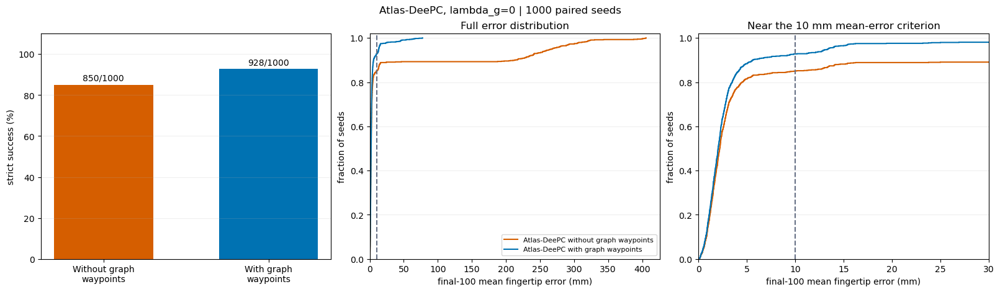

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for i, mode in enumerate(METHODS):
    rows = frame[frame['mode'] == mode]
    rate = 100*rows.strict.mean()
    axes[0].bar(i, rate, color=COLORS[mode], width=.6)
    axes[0].text(i, rate+2, f"{rows.strict.sum()}/{len(rows)}", ha="center")
    values = np.sort(rows.mean_error_mm)
    for ax in axes[1:]:
        ax.step(np.r_[0, values], np.r_[0, np.arange(1, len(values)+1)/len(values)],
                where="post", color=COLORS[mode], label=METHODS[mode])
axes[0].set(xticks=[0,1], xticklabels=["Without graph\nwaypoints", "With graph\nwaypoints"],
            ylim=(0,110), ylabel="strict success (%)")
for ax in axes[1:]:
    ax.axvline(10, color="#667085", linestyle="--")
    ax.set(xlim=(0,None), ylim=(0,1.02), xlabel="final-100 mean fingertip error (mm)", ylabel="fraction of seeds")
axes[1].set_title("Full error distribution")
axes[2].set(xlim=(0,30), title="Near the 10 mm mean-error criterion")
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y", alpha=.2)
fig.suptitle(f"Atlas-DeePC, lambda_g=0 | {len(EVALUATION_SEEDS)} paired seeds")
fig.savefig(RESULT_ROOT / "paired_success_and_error.png", dpi=160)
plt.show()


## 4. Computation Time by Module

The methods use matching workers and settings; method order alternates across
seeds. The first five steps per rollout are excluded. Timings are pooled over the
requested seeds. QP time includes construction, canonicalization and solve.
Offline SVD, simulator stepping, saving, and video rendering are excluded.

Stacked **means** add to the mean total. Median and P99 module times are shown
separately because percentiles do not add. Terminal-reference selection still
uses graph costs in both methods. These are shared-computer wall-clock timings,
not an isolated hardware benchmark.

In the no-waypoint variant, the small time recorded under "Graph routing" is
branch/reference bookkeeping, not a waypoint-route search. The common route-cost
terminal selection is timed separately under "Terminal-reference selection".


mean_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.1646   
Graph routing                                          0.0179   
Linear subspace retrieval                              0.0020   
Other control-loop work                                0.0912   
QP construction and solve                             84.1234   
Terminal-reference selection                           0.0404   
Total online control                                  84.4395   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.1653   
Graph routing                                             0.0127   
Linear subspace retrieval                                 0.0019   
Other control-loop work                                   0.0914   
QP construction and solve                                85.7912   
Terminal-reference selection                              0.0400   
Total online control                                     86.1025   

                                                    median_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.0700   
Graph routing                                          0.0065   
Linear subspace retrieval                              0.0008   
Other control-loop work                                0.0370   
QP construction and solve                             79.3570   
Terminal-reference selection                           0.0158   
Total online control                                  79.6724   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.0700   
Graph routing                                             0.0043   
Linear subspace retrieval                                 0.0009   
Other control-loop work                                   0.0368   
QP construction and solve                                80.8011   
Terminal-reference selection                              0.0158   
Total online control                                     81.0943   

                                                       p99_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     2.6973   
Graph routing                                          0.0628   
Linear subspace retrieval                              0.0023   
Other control-loop work                                1.4653   
QP construction and solve                            200.7567   
Terminal-reference selection                           0.3220   
Total online control                                 201.4257   

                                                                  
Method                       Atlas-DeePC without graph waypoints  
module                                                            
Chart localization                                        2.7268  
Graph routing                                             0.0395  
Linear subspace retrieval                                 0.0023  
Other control-loop work                                   1.5089  
QP construction and solve                               203.8962  
Terminal-reference selection                              0.3188  
Total online control                                    204.5830

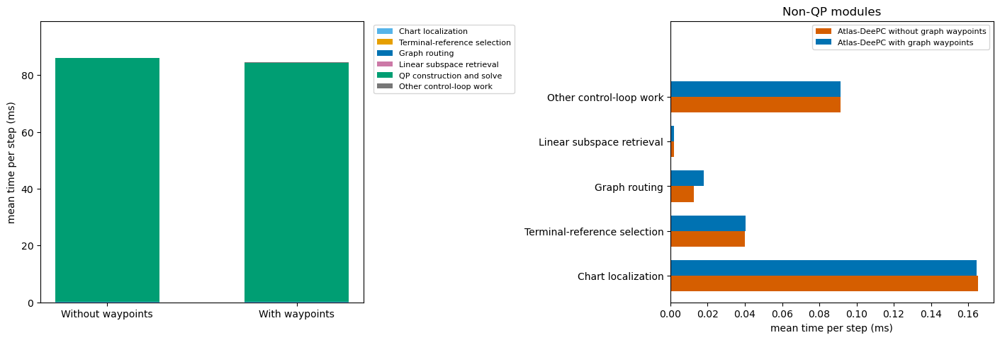

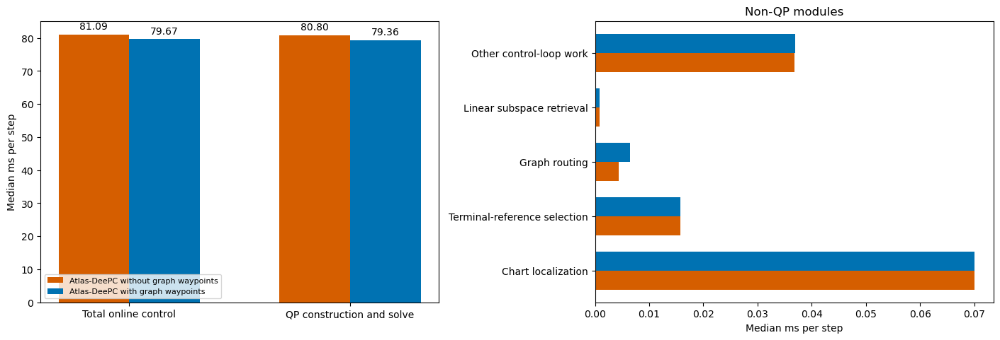

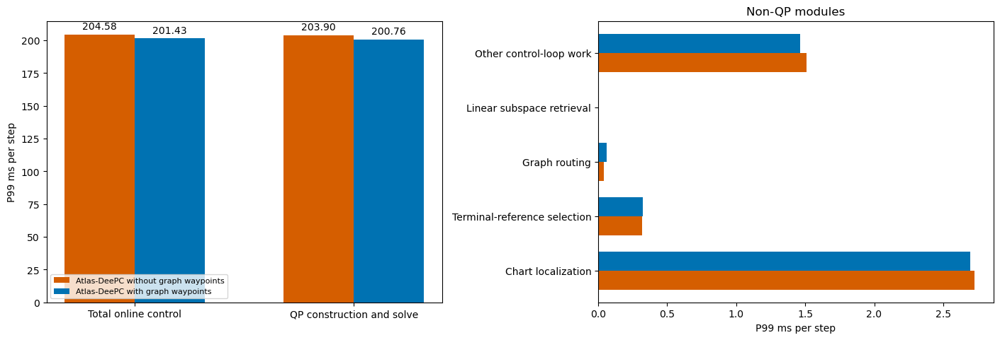

,Atlas-DeePC without graph waypoints,Atlas-DeePC with graph waypoints
One-time candidate setup (ms),,
mean,9.362950,9.194993
median,6.526084,6.576729
p95,23.064219,23.015750


In [8]:
from baseline_1000_benchmark import summarize_timing
timings = {}
for mode in METHODS:
    if set(EVALUATION_SEEDS) == set(payload["seeds"]):
        timings[mode] = payload["panels"][mode]["timing"]
    else:
        timings[mode] = summarize_timing([RESULT_ROOT/mode/f"seed{s}_control_results.npz" for s in EVALUATION_SEEDS])
    assert timings[mode]["timed_steps"] == len(EVALUATION_SEEDS)*(config.steps-5)
timing = pd.DataFrame([{"mode": mode, "Method": METHODS[mode], **entry}
    for mode, data in timings.items() for entry in data["modules"]])
display(timing.pivot(index="module", columns="Method", values=["mean_ms", "median_ms", "p99_ms"]).round(4))
module_names = [x for x in timing.module.unique() if x != "Total online control"]
palette = ["#56B4E9", "#E69F00", "#0072B2", "#CC79A7", "#009E73", "#777777"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7), constrained_layout=True)
bottom = np.zeros(2)
for name, color in zip(module_names, palette):
    values = np.array([timing.loc[(timing['mode']==mode)&(timing.module==name), "mean_ms"].item() for mode in METHODS])
    axes[0].bar([0,1], values, bottom=bottom, color=color, label=name, width=.55)
    bottom += values
axes[0].set(xticks=[0,1], xticklabels=["Without waypoints", "With waypoints"], ylim=(0,bottom.max()*1.15), ylabel="mean time per step (ms)")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02,1))
overhead = [name for name in module_names if name != "QP construction and solve"]
y = np.arange(len(overhead))
for i, mode in enumerate(METHODS):
    values = [timing.loc[(timing['mode']==mode)&(timing.module==name), "mean_ms"].item() for name in overhead]
    axes[1].barh(y+(i-.5)*.35, values, height=.35, color=COLORS[mode], label=METHODS[mode])
axes[1].set(yticks=y, yticklabels=overhead, xlabel="mean time per step (ms)", title="Non-QP modules")
axes[1].set_ylim(-.6, len(overhead)+.7)
axes[1].legend(fontsize=8, loc="upper right")
fig.savefig(RESULT_ROOT/"paired_module_mean_times.png", dpi=160)
plt.show()
for statistic, label in [("median_ms","Median"),("p99_ms","P99")]:
    fig, axes = plt.subplots(1,2,figsize=(14,4.7),constrained_layout=True)
    for i, mode in enumerate(METHODS):
        values = [timing.loc[(timing['mode']==mode)&(timing.module==name), statistic].item() for name in ("Total online control","QP construction and solve")]
        bars = axes[0].bar(np.arange(2)+(i-.5)*.32,values,width=.32,color=COLORS[mode],label=METHODS[mode])
        axes[0].bar_label(bars,fmt="%.2f",padding=3)
        values = [timing.loc[(timing['mode']==mode)&(timing.module==name), statistic].item() for name in overhead]
        axes[1].barh(y+(i-.5)*.35,values,height=.35,color=COLORS[mode])
    axes[0].set(xticks=[0,1],xticklabels=["Total online control","QP construction and solve"],ylabel=f"{label} ms per step")
    axes[0].set_ylim(bottom=0)
    axes[0].margins(y=.2)
    axes[0].legend(fontsize=8)
    axes[1].set(yticks=y,yticklabels=overhead,xlabel=f"{label} ms per step",title="Non-QP modules")
    fig.savefig(RESULT_ROOT/f"paired_module_{statistic}.png",dpi=160)
    plt.show()
display(pd.DataFrame({METHODS[mode]: data["one_time_goal_setup_ms"] for mode,data in timings.items()}).rename_axis("One-time candidate setup (ms)"))


## 5. Paired Rollout Videos

Each pair uses the same seed and target. Videos replay saved actions, with measured
outputs checked against the numerical traces. Outcome labels use the complete
320-step run, not the displayed video duration. These selected examples are
diagnostic illustrations; the full evaluation above determines the success rate.


In [9]:
import base64
from baseline_waypoint_media import prepare_media, GALLERY_SEEDS, DASHBOARD_SEEDS
from render_routed_deepc_dashboard import file_sha256
PREPARE_MEDIA = False
if PREPARE_MEDIA:
    prepare_media(RESULT_ROOT)
MEDIA_DIR = RESULT_ROOT / "videos"
def media_uri(path, mime):
    return "data:"+mime+";base64,"+base64.b64encode(Path(path).read_bytes()).decode("ascii")
def show_pair(seed, dashboard=False):
    cards = []
    for mode in METHODS:
        row = rows_by_mode[mode][seed]
        name = f"{mode}_seed{seed}" + ("_025x" if dashboard else "_replay")
        video = MEDIA_DIR / (name+".mp4")
        metadata = json.loads((MEDIA_DIR/(name+".json")).read_text())
        trace_path = RESULT_ROOT/mode/f"seed{seed}_control_results.npz"
        assert metadata["source_result_sha256"] == file_sha256(trace_path)
        assert metadata["lam_g"] == 0 and metadata["reference_mode"] == mode
        success = bool(row["success_30"] and row["success_100"])
        status = "STRICT SUCCESS" if success else "STRICT FAILURE"
        color = "#166534" if success else "#b91c1c"
        poster = ""
        detail = f"Final-100 mean: {1000*row['mean_last_100']:.3f} mm | lambda_g=0"
        if dashboard:
            assert metadata["play_speed"] == .25
            assert metadata["dashboard_renderer_sha256"] == file_sha256(ROOT/"src/render_routed_deepc_dashboard.py")
            detail += f" | 0.25x | {metadata['displayed_control_steps']}/{metadata['saved_control_steps']} steps shown"
            poster_path = MEDIA_DIR/(name+"_poster.png")
            poster = f' poster="{media_uri(poster_path, "image/png")}"'
        else:
            assert metadata["maximum_replay_output_error"] <= 1e-8
        cards.append(f'<div style="background:#fff;color:#111827;padding:10px;border:1px solid #d1d5db;min-width:0">'
            f'<h4 style="margin:0 0 6px">Seed {seed}: {METHODS[mode]}</h4>'
            f'<p style="margin:0 0 8px;color:{color}">{status}</p><p style="font-size:12px">{detail}</p>'
            f'<video controls preload="metadata"{poster} src="{media_uri(video,"video/mp4")}" style="width:100%;display:block"></video></div>')
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(min(480px,100%),1fr));gap:12px;margin-bottom:16px">'+''.join(cards)+'</div>'))
for seed in GALLERY_SEEDS:
    if seed in EVALUATION_SEEDS:
        show_pair(seed)


## 6. Slowed Control and Chart Diagnostics

The 0.25x dashboards show the arm, DeePC prediction, active reference, measured
charts, true fingertip error, and inputs. A successful rollout may have its settled
tail omitted for display only; failures retain the full rollout so late drift is
visible. Playback speed follows the existing dashboard convention (20 control
samples per second at 1x), not a claim about real-time solver execution.



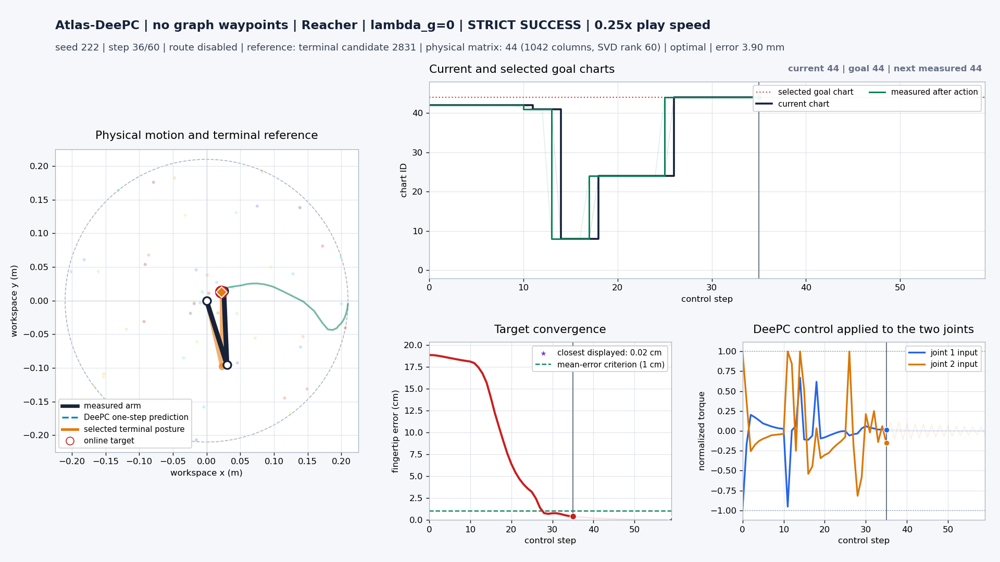
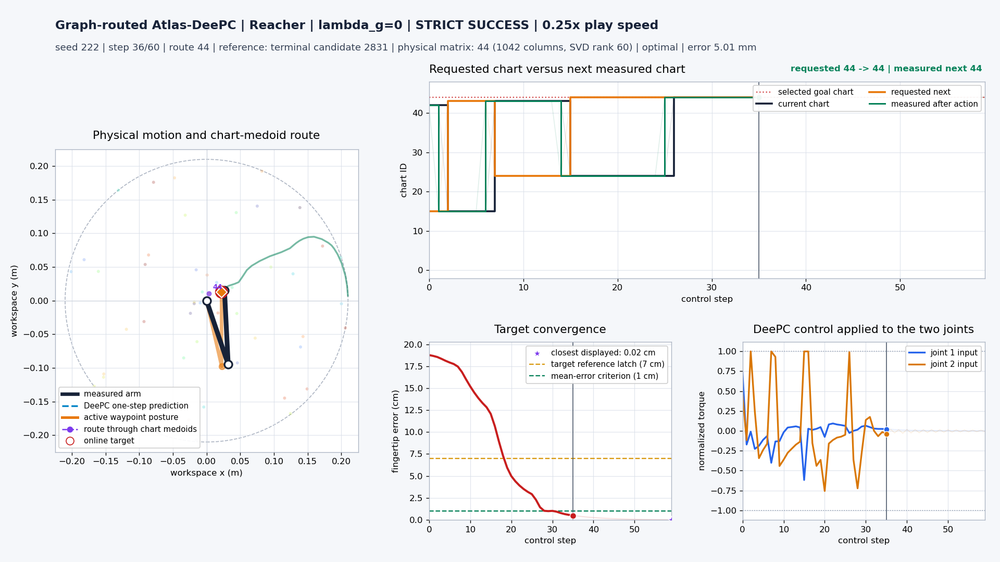


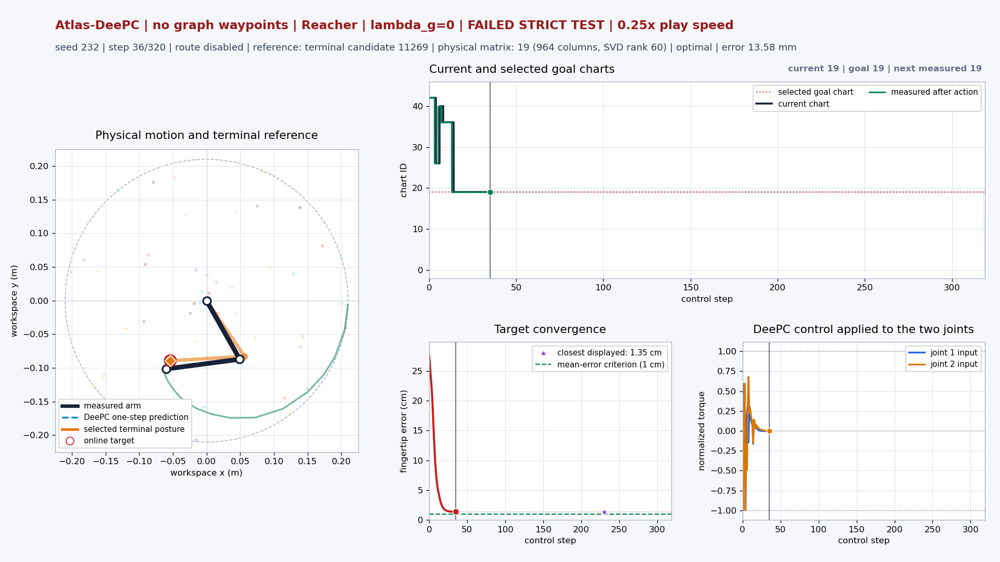
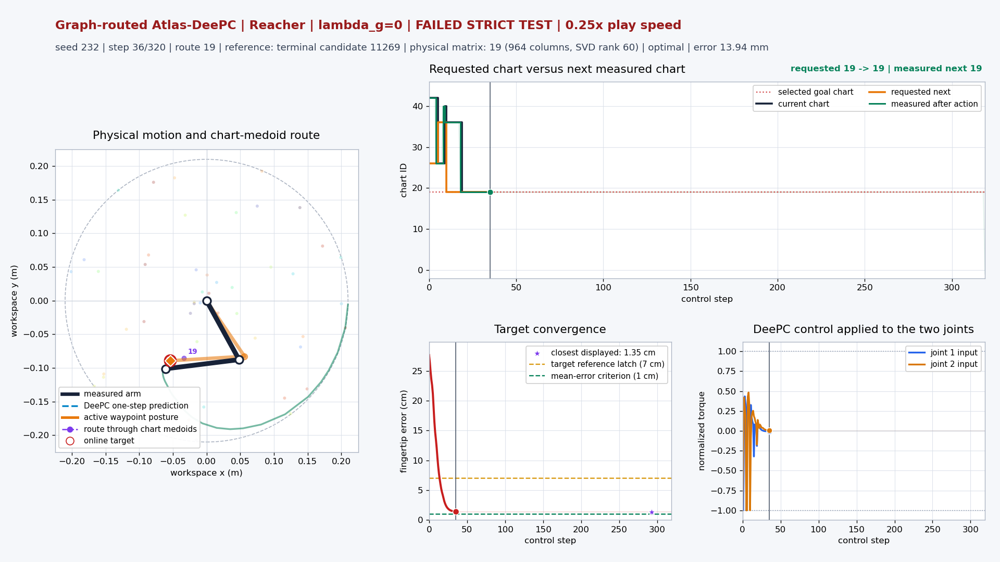


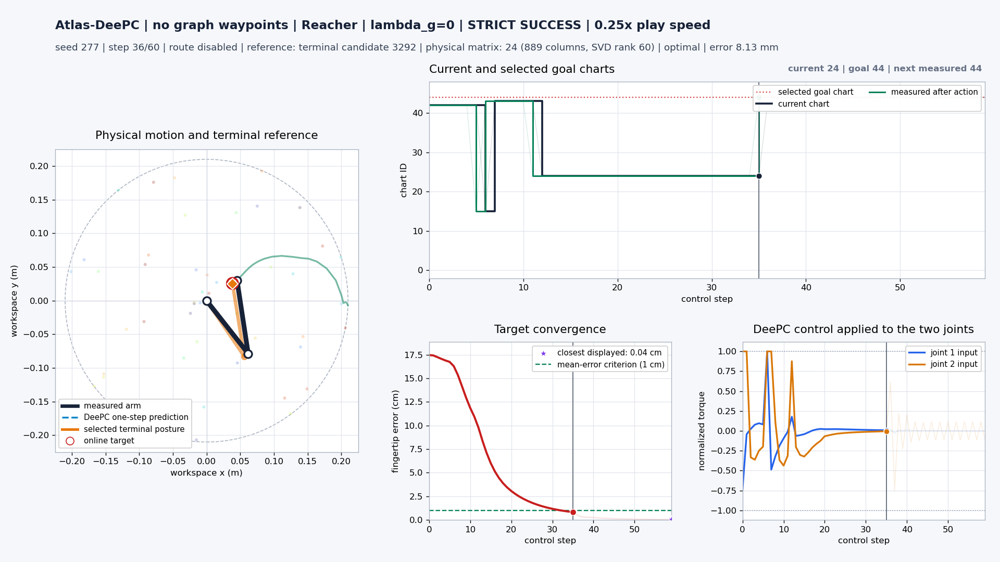
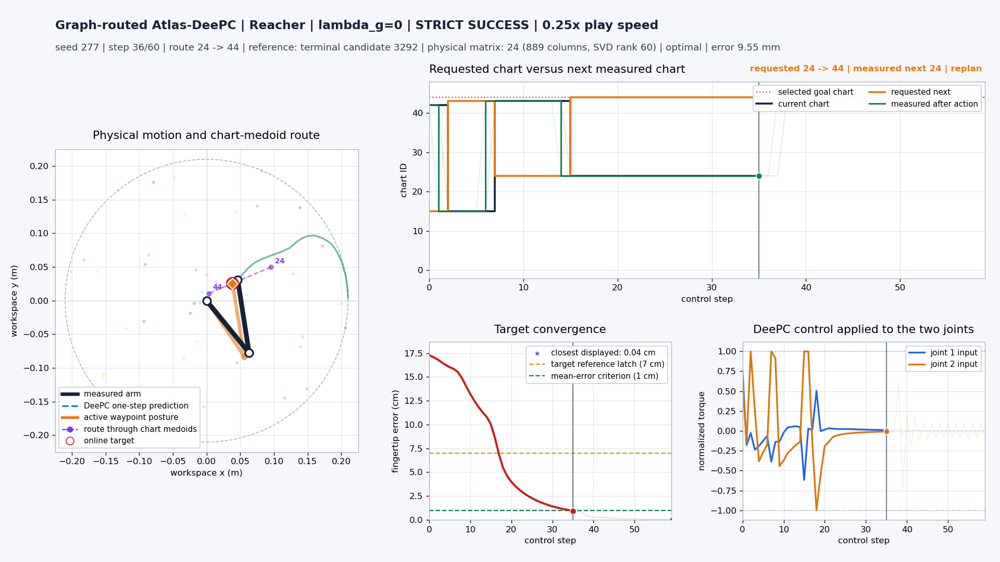

In [10]:
for seed in DASHBOARD_SEEDS:
    if seed in EVALUATION_SEEDS:
        show_pair(seed, dashboard=True)


## 7. Reproduction and Version Boundary

Edit `EVALUATION_SEEDS` at the top and enable `RUN_EVALUATION` to run both methods
on another range. Results resume per seed and incompatible caches are rejected.
`PREPARE_MEDIA` regenerates the gallery from the saved numerical traces.

The nominal `baseline.default_config()` now sets lambda_g=0. The default
`BaselineAtlasDeePC.run(...)` uses graph waypoints; pass `reference_mode="terminal"`
to omit intermediate waypoints while retaining N=10 route-cost goal selection.
The historical lower-level `RoutedDeePCConfig` default remains lambda_g=0.05 to
avoid silently changing archived experiments that explicitly use it.

The new result root is `baseline.RESULT_ROOT`; old results and the previous
baseline notebook are archived, not relabeled. The separate comparison notebooks
and the rank-ablation experiments are not rerun or mixed into this report.


## 8. OSQP Solver Comparison

This experiment changes **only the QP solver** from Clarabel to OSQP for both
baseline variants. Lambda_g remains zero. The data, 48 charts, rank 60, N=10
terminal selection, costs, constraints, seeds and 320-step rollout length remain
the same. The Clarabel results above are preserved.

The existing controller creates a new CVXPY Problem at each step. Consequently,
this is a **direct solver substitution**, not an optimized persistent OSQP
workspace with cross-step warm starts or cached factorizations.

OSQP uses the existing 10,000-iteration cap and the installed CVXPY adapter's
defaults: absolute and relative tolerances 1e-5, with polishing enabled. The
manifest records CVXPY and OSQP versions. A non-solved QP retains the existing
zero-action behavior; there is no fallback to Clarabel. Such steps remain in
the success/error statistics and are counted explicitly.

Success outcomes use all requested seeds. The latency comparison excludes pilot
seeds 222 and 237 from **both** solvers: those OSQP compatibility tests used two
workers, while the main panel uses four. For the default range this gives 998
paired timing seeds, discarding the first five steps of each rollout. Measurements
remain shared-computer wall-clock times, not an isolated hardware benchmark.


In [11]:
import baseline_osqp_comparison as osqp_experiment
RUN_OSQP = False
OSQP_RESULT_ROOT = osqp_experiment.RESULT_ROOT
if RUN_OSQP:
    osqp_experiment.run_panel(EVALUATION_SEEDS, OSQP_RESULT_ROOT, WORKERS)
osqp_payload = json.loads((OSQP_RESULT_ROOT / "summary.json").read_text())
assert osqp_payload["version"] == osqp_experiment.VERSION
assert osqp_payload["signature"]["solver"] == "OSQP"
assert osqp_payload["signature"]["config"] == payload["signature"]["config"] == asdict(config)
for key in ("data_sha256", "atlas_sha256"):
    assert osqp_payload["signature"][key] == payload["signature"][key]
for name, digest in payload["signature"]["source_sha256"].items():
    assert osqp_payload["signature"]["source_sha256"][name] == digest
solver_rows = {"Clarabel": rows_by_mode, "OSQP": {}}
for mode in METHODS:
    rows = {int(r["seed"]): r for r in osqp_payload["panels"][mode]["results"]}
    missing = sorted(set(EVALUATION_SEEDS)-set(rows))
    assert not missing, f"OSQP {mode}: missing {len(missing)} requested seeds. Enable RUN_OSQP."
    solver_rows["OSQP"][mode] = {s: rows[s] for s in EVALUATION_SEEDS}
    for seed, row in solver_rows["OSQP"][mode].items():
        assert row["solver"] == "OSQP" and row["lam_g"] == 0
        assert row["solver_ablation_version"] == osqp_experiment.VERSION
        assert row["matrix_geometry"] == "linear" and row["candidate_count"] == 10
        assert row["steps"] == config.steps and row["reference_mode"] == mode
        assert row["minimum_selected_goal_source_separation"] >= .06
        np.testing.assert_array_equal(row["exact_target_xy"], solver_rows["Clarabel"][mode][seed]["exact_target_xy"])
solver_report = pd.DataFrame([{
    "Waypoints": "With" if mode == "graph" else "Without", "Solver": solver,
    "Successes": sum(bool(r["success_30"] and r["success_100"]) for r in rows.values()),
    "Seeds": len(rows),
    "Success rate (%)": 100*np.mean([r["success_30"] and r["success_100"] for r in rows.values()]),
    "Median final-100 mean (mm)": 1000*np.median([r["mean_last_100"] for r in rows.values()]),
    "P90 final-100 mean (mm)": 1000*np.percentile([r["mean_last_100"] for r in rows.values()],90),
    "Unsolved QPs": sum(r["unsolved_steps"] for r in rows.values()),
} for mode in METHODS for solver, modes in solver_rows.items() for rows in [modes[mode]]])
display(solver_report.set_index(["Waypoints","Solver"]).round(3))
paired_solver_changes = []
for mode in METHODS:
    a = solver_rows["Clarabel"][mode]
    b = solver_rows["OSQP"][mode]
    success = lambda row: bool(row["success_30"] and row["success_100"])
    osqp_only = [s for s in EVALUATION_SEEDS if success(b[s]) and not success(a[s])]
    clarabel_only = [s for s in EVALUATION_SEEDS if success(a[s]) and not success(b[s])]
    paired_solver_changes.append({"Waypoints": "With" if mode == "graph" else "Without",
        "OSQP-only successes": len(osqp_only), "Clarabel-only successes": len(clarabel_only),
        "Net change with OSQP": len(osqp_only)-len(clarabel_only)})
display(pd.DataFrame(paired_solver_changes).set_index("Waypoints"))
solver_report.to_json(OSQP_RESULT_ROOT/"solver_comparison_report.json",orient="records",indent=2)
SOLVER_COLORS = {"Clarabel":"#0072B2", "OSQP":"#D55E00"}
fig, axes = plt.subplots(1,3,figsize=(16,4.7),constrained_layout=True)
for i, solver in enumerate(solver_rows):
    values = [100*np.mean([r["success_30"] and r["success_100"] for r in solver_rows[solver][mode].values()]) for mode in METHODS]
    bars = axes[0].bar(np.arange(2)+(i-.5)*.34, values, width=.34, color=SOLVER_COLORS[solver],label=solver)
    axes[0].bar_label(bars,fmt="%.1f%%",padding=3)
    for ax,mode in zip(axes[1:],METHODS):
        values = np.sort([1000*r["mean_last_100"] for r in solver_rows[solver][mode].values()])
        ax.step(np.r_[0,values],np.r_[0,np.arange(1,len(values)+1)/len(values)],where="post",color=SOLVER_COLORS[solver],linestyle="--" if solver=="OSQP" else "-",linewidth=2,label=solver)
axes[0].set(xticks=[0,1],xticklabels=["Without waypoints","With waypoints"],ylim=(0,110),ylabel="strict success (%)")
axes[0].legend()
for ax,mode in zip(axes[1:],METHODS):
    ax.set(xlim=(0,30),ylim=(0,1.02),xlabel="final-100 mean fingertip error (mm)",ylabel="fraction of seeds",title=METHODS[mode])
    ax.axvline(10,color="#667085",linestyle="--")
for ax in axes: ax.grid(axis="y",alpha=.2)
fig.suptitle(f"Direct solver substitution | lambda_g=0 | {len(EVALUATION_SEEDS)} paired seeds")
fig.savefig(OSQP_RESULT_ROOT/"osqp_success_and_error.png",dpi=160)
plt.show()


Successes  Seeds  Success rate (%)  \
Waypoints Solver                                         
Without   Clarabel        850   1000              85.0   
          OSQP            850   1000              85.0   
With      Clarabel        928   1000              92.8   
          OSQP            928   1000              92.8   

                    Median final-100 mean (mm)  P90 final-100 mean (mm)  \
Waypoints Solver                                                          
Without   Clarabel                       2.199                  212.697   
          OSQP                           2.199                  212.697   
With      Clarabel                       2.032                    5.586   
          OSQP                           2.032                    5.586   

                    Unsolved QPs  
Waypoints Solver                  
Without   Clarabel             0  
          OSQP                 0  
With      Clarabel             0  
          OSQP                 0

,OSQP-only successes,Clarabel-only successes,Net change with OSQP
Waypoints,,,
Without,0,0,0
With,0,0,0


/var/folders/xs/3mv1bwyj13v1t190pcxlvckc0000gn/T/ipykernel_26375/2582050773.py:66: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [12]:
TIMING_SEEDS = [s for s in EVALUATION_SEEDS if s not in {222,237}]
assert TIMING_SEEDS, "Timing needs at least one seed other than the two pilot seeds."
solver_timings = {}
for solver, directory in [("Clarabel",RESULT_ROOT),("OSQP",OSQP_RESULT_ROOT)]:
    for mode in METHODS:
        solver_timings[solver,mode] = summarize_timing([directory/mode/f"seed{s}_control_results.npz" for s in TIMING_SEEDS])
        assert solver_timings[solver,mode]["timed_steps"] == len(TIMING_SEEDS)*(config.steps-5)
solver_timing_table = pd.DataFrame([{
    "Solver":solver,"Waypoints":"With" if mode=="graph" else "Without",**row
} for (solver,mode), data in solver_timings.items() for row in data["modules"]])
display(pd.Series({"paired timing seeds":len(TIMING_SEEDS),"timed steps per method/solver":len(TIMING_SEEDS)*(config.steps-5),"main-panel workers":4}))
display(solver_timing_table.pivot(index="module",columns=["Waypoints","Solver"],values=["mean_ms","median_ms","p99_ms"]).round(4))
fig, axes = plt.subplots(1,3,figsize=(15,4.7),constrained_layout=True)
for ax,stat,label in zip(axes,["mean_ms","median_ms","p99_ms"],["Mean","Median","P99"]):
    for i,solver in enumerate(solver_rows):
        values = [solver_timing_table.loc[(solver_timing_table.Solver==solver)&(solver_timing_table.Waypoints==("With" if mode=="graph" else "Without"))&(solver_timing_table.module=="Total online control"),stat].item() for mode in METHODS]
        bars=ax.bar(np.arange(2)+(i-.5)*.34,values,width=.34,color=SOLVER_COLORS[solver],label=solver)
        ax.bar_label(bars,fmt="%.2f",padding=3)
    ax.set(xticks=[0,1],xticklabels=["Without waypoints","With waypoints"],ylabel=f"{label} online time per step (ms)")
    ax.margins(y=.2)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y",alpha=.2)
axes[0].legend()
fig.suptitle(f"Shared-computer timing | {len(TIMING_SEEDS)} paired seeds | first five steps excluded")
fig.savefig(OSQP_RESULT_ROOT/"osqp_online_timing.png",dpi=160)
plt.show()
solver_timing_table.to_json(OSQP_RESULT_ROOT/"solver_module_timing_report.json",orient="records",indent=2)


paired timing seeds                 998
timed steps per method/solver    314370
main-panel workers                    4
dtype: int64

mean_ms                            median_ms  \
Waypoints                     Without     With  Without     With   Without   
Solver                       Clarabel Clarabel     OSQP     OSQP  Clarabel   
module                                                                       
Chart localization             0.1652   0.1646   0.0864   0.0897    0.0700   
Graph routing                  0.0127   0.0179   0.0058   0.0086    0.0043   
Linear subspace retrieval      0.0019   0.0020   0.0009   0.0010    0.0009   
Other control-loop work        0.0915   0.0913   0.0444   0.0451    0.0368   
QP construction and solve     85.7763  84.1167  80.0292  79.1396   80.7880   
Terminal-reference selection   0.0400   0.0404   0.0196   0.0202    0.0158   
Total online control          86.0876  84.4329  80.1863  79.3043   81.0791   

                                                           p99_ms            \
Waypoints                        With  Without     With   Without      With   
Solver                       Clarabel     OSQP     OSQP  Clarabel  Clarabel   
module                                                                        
Chart localization             0.0700   0.0697   0.0696    2.7233    2.6976   
Graph routing                  0.0065   0.0043   0.0063    0.0396    0.0628   
Linear subspace retrieval      0.0008   0.0007   0.0007    0.0023    0.0023   
Other control-loop work        0.0370   0.0335   0.0337    1.5098    1.4674   
QP construction and solve     79.3542  69.2851  68.3302  203.8900  200.7370   
Terminal-reference selection   0.0158   0.0153   0.0153    0.3188    0.3227   
Total online control          79.6678  69.4238  68.4717  204.5681  201.3771   

                                                  
Waypoints                      Without      With  
Solver                            OSQP      OSQP  
module                                            
Chart localization              0.3751    0.3806  
Graph routing                   0.0168    0.0261  
Linear subspace retrieval       0.0020    0.0020  
Other control-loop work         0.1895    0.1980  
QP construction and solve     281.4862  292.4116  
Terminal-reference selection    0.0738    0.0733  
Total online control          281.7779  292.7639

/var/folders/xs/3mv1bwyj13v1t190pcxlvckc0000gn/T/ipykernel_26375/2513117930.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### OSQP Numerical Diagnostics

These diagnostic summaries include all 320 control steps and all requested seeds,
including the two pilot seeds. Iteration/residual statistics use steps for which
CVXPY returned solver statistics. Exceptions can lack those statistics and are
counted separately. `optimal_inaccurate` is accepted by the unchanged controller;
it is not silently treated as an exact solve. The reported OSQP backend time is
not the full controller latency shown above.


In [13]:
osqp_diagnostics = {}
diagnostic_rows = []
for mode in METHODS:
    records = []
    statuses = []
    for seed in EVALUATION_SEEDS:
        with np.load(OSQP_RESULT_ROOT/mode/f"seed{seed}_control_results.npz",allow_pickle=True) as trace:
            rec = json.loads(trace["solver_diagnostics"].item())
            assert len(rec)==config.steps and all(r["solver"]=="OSQP" for r in rec)
            np.testing.assert_allclose(trace["distance"],np.linalg.norm(trace["y"][:,6:8]-trace["final_goal"].reshape(-1)[6:8],axis=1))
            records.extend(rec)
            statuses.extend(trace["status"].astype(str).tolist())
    osqp_diagnostics[mode] = records
    iterations = [r["iterations"] for r in records if r["iterations"] is not None]
    backend_ms = [1000*r["solver_reported_time_s"] for r in records if r["solver_reported_time_s"] is not None]
    diagnostic_rows.append({"Waypoints":"With" if mode=="graph" else "Without",
        "Total QPs":len(records),"Optimal":statuses.count("optimal"),
        "Optimal inaccurate":statuses.count("optimal_inaccurate"),
        "Exceptions":sum(r["error"] is not None for r in records),
        "Steps with iteration stats":len(iterations),
        "Median iterations":np.median(iterations) if iterations else np.nan,
        "P99 iterations":np.percentile(iterations,99) if iterations else np.nan,
        "Median backend-reported time (ms)":np.median(backend_ms) if backend_ms else np.nan})
diagnostic_report=pd.DataFrame(diagnostic_rows).set_index("Waypoints")
display(diagnostic_report.round(3))
diagnostic_report.to_json(OSQP_RESULT_ROOT/"osqp_diagnostic_report.json",orient="index",indent=2)


,Total QPs,Optimal,Optimal inaccurate,Exceptions,Steps with iteration stats,Median iterations,P99 iterations,Median backend-reported time (ms)
Waypoints,,,,,,,,
Without,320000,319993,7,0,320000,1425.0,7625.0,44.521
With,320000,319999,1,0,320000,1375.0,7700.0,43.509
